# 02 · Rotation building — chains, turns, minimum turnaround and buffer

**Buffer Delay Allocation Engine · Phase 2** (data contract v1.1)

This notebook turns the 1.64 million AA flights of the Phase 1 base table into aircraft **chains**, builds
the **turns** between consecutive legs, estimates the **minimum turnaround time (MTT)**, derives the
**planned buffer**, and tests the premise the whole project rests on: *does planned buffer absorb delay?*

**Inputs:** `interim/aa_base_2025_2026.parquet`, `reference/airports_tz.csv`.
**Outputs** (all under `processed/`): `rotations.parquet` (one row per flight), `rotation_turns.parquet`,
`rotation_breaks.parquet`, `mtt_sensitivity.parquet`, plus small CSVs. Built by
`bufferengine.pipeline.build_rotations`; the analysis functions are in `bufferengine.pipeline.rotation_audit`.

**Provenance.** Flights, delays and `LateAircraftDelay` are **real** BTS data. Chain links, UTC times, ground
times and buffer are **derived**. **MTT is an assumption** (estimated from data, with sensitivity), so
`planned_buffer_min` is an assumption-dependent derived field. Nothing here is synthetic.

**Rules.**
1. Chains use **operated** flights only. Cancelled and diverted flights stay in the aircraft's sequence but **break** the chain.
2. Per aircraft, legs are ordered by scheduled UTC departure. Consecutive legs link only if previous Dest = next Origin **and** the next scheduled departure is not before the previous scheduled arrival. A pair failing the second test is a **tail swap** (BTS reports the aircraft that actually flew): the chain breaks and the pair is counted.
3. **Operating day:** a new operating day starts when scheduled ground time exceeds **300 minutes** (the aircraft rests; the 240–300 minute bucket is the valley between daytime turns and overnight rests in the data). A leg crossing midnight, and an early leg following a short turn after it, stay in the same operating day.
4. A **segment** is a run of linked operated legs. Segments of 2+ legs are **usable**; single-leg segments are kept with `usable = false`.
5. Splits: train = 2025-01 to 2025-09, validate = 2025-10 to 2025-12, test = 2026-01 to 2026-08. **MTT is estimated from train turns only.**

In [1]:
import os, sys
from pathlib import Path

IN_DATABRICKS = "DATABRICKS_RUNTIME_VERSION" in os.environ
if IN_DATABRICKS:
    os.environ.setdefault("DATA_ROOT", "/Volumes/workspace/default/bufferengine")
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckdb"])

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bufferengine import config
from bufferengine.pipeline import build_rotations as B
from bufferengine.pipeline import rotation_audit as R

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100})
BLUE, ORANGE, GREY, GREEN, RED = "#1f6fb2", "#d9822b", "#8a94a6", "#2a9d6f", "#c0392b"

print("DATA_ROOT:", config.data_root())
tables = R.load_tables()
legs, turns, breaks, sens = tables["legs"], tables["turns"], tables["breaks"], tables["sens"]
base_total = duckdb.sql(f"SELECT COUNT(*) FROM read_parquet('{config.base_table_path().as_posix()}')").fetchone()[0]
print(f"base flights {base_total:,} | rotations rows {len(legs):,} | turns {len(turns):,} | breaks {len(breaks):,}")

DATA_ROOT: C:\Users\vaibh\OneDrive\Desktop\Capstone Project\Buffer Delay Allocation\buffer-allocation-engine\data


base flights 1,641,071 | rotations rows 1,641,071 | turns 1,045,807 | breaks 93,458


## 1. Where every flight went (reconciliation)

Each of the base flights is in exactly one category. Priority when several apply: cancelled, diverted, missing tail, then chain position.

,category,flights,pct
0,usable_segment,1408848,85.849
1,single_leg_segment,191021,11.640
2,cancelled,35245,2.148
3,diverted,5957,0.363
4,missing_tail,0,0.000
5,other,0,0.000
6,TOTAL,1641071,100.000


check: categories sum to 1,641,071 = base table 1,641,071  -> OK
flights with no tail number: 11 | their category: {'cancelled': 11}


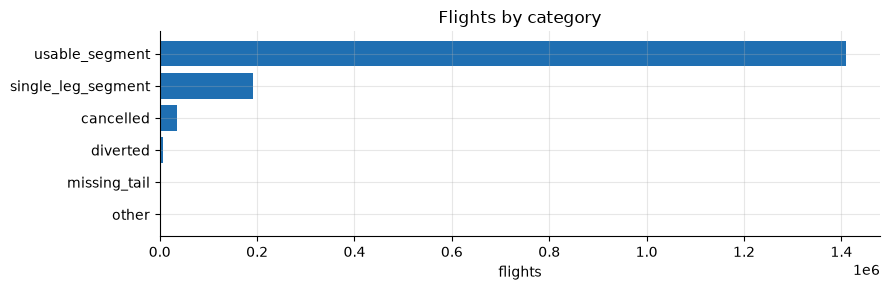

In [2]:
rec = B.reconciliation(legs, base_total=base_total)        # raises if the counts do not add up
total = pd.DataFrame([{"category": "TOTAL", "flights": int(rec["flights"].sum()), "pct": 100.0}])
display(pd.concat([rec, total], ignore_index=True))
print(f"check: categories sum to {int(rec['flights'].sum()):,} = base table {base_total:,}  ->",
      "OK" if int(rec["flights"].sum()) == base_total else "MISMATCH")
print("flights with no tail number:", int(legs["tail_number"].isna().sum()),
      "| their category:", legs.loc[legs["tail_number"].isna(), "category"].value_counts().to_dict())
fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(rec["category"][::-1], rec["flights"][::-1], color=BLUE); ax.set_xlabel("flights")
ax.set_title("Flights by category"); plt.tight_layout(); plt.show()

**Old contract v1.0 rule versus the new segment rule** (tail-days, i.e. one aircraft on one FlightDate):

In [3]:
cmp_ = pd.read_csv(config.processed_dir() / "rotation_rule_comparison.csv")
cmp_

,rule,count,legs
0,tail-days with a tail number (all flights),478938,1641060
1,OLD v1.0 rule: usable tail-days (cancelled leg...,405613,1494403
2,NEW v1.1 rule: tail-days with at least one usa...,384708,1408848
3,NEW v1.1 rule: tail-days that are one single u...,306913,1162136
4,NEW v1.1 rule: usable segments,363041,1408848


**What this shows.** All **1,641,071** flights are accounted for, each in exactly one category:
**1,408,848 (85.85%)** are legs in a usable segment (363,041 segments of 2+ legs), **191,021 (11.64%)** are
legs whose segment has only one leg, **35,245 (2.15%)** are cancelled and **5,957 (0.36%)** diverted.
`missing_tail` and `other` are 0: the 11 flights with no tail number are all cancelled flights, which the
priority order counts as cancelled.

**Old rule versus new rule.** Under the v1.0 contract rule (cancelled legs removed and chained through, swaps kept),
**405,613 tail-days** were usable, holding 1,494,403 legs. Under the v1.1 segment rule, **384,708 tail-days
contain at least one usable segment**, holding **1,408,848 legs (5.7% fewer)**, and **306,913 tail-days are one
single clean segment** (1,162,136 legs). The new rule is stricter on purpose: cancelled flights and tail swaps now break
chains instead of being skipped or flagged.

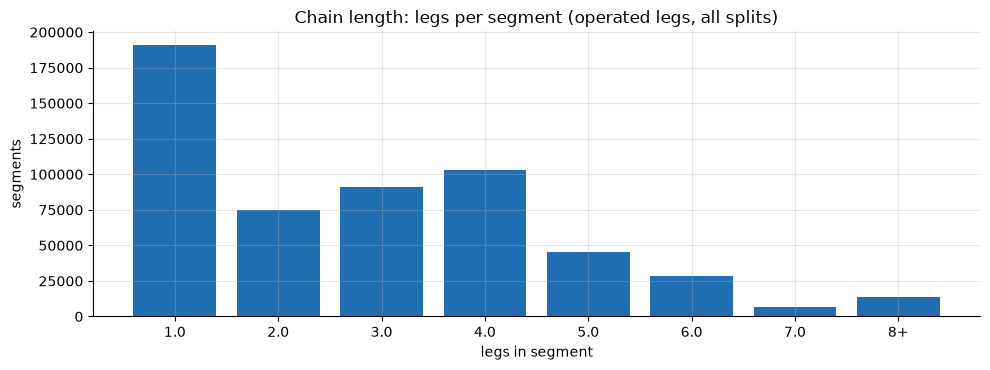

,legs_in_segment,segments,legs,pct_of_segments
0,1.0,191021,191021.0,34.48
1,2.0,74966,149932.0,13.53
2,3.0,90889,272667.0,16.40
3,4.0,102757,411028.0,18.55
4,5.0,45601,228005.0,8.23
5,6.0,28468,170808.0,5.14
6,7.0,6931,48517.0,1.25
7,8+,13429,107432.0,2.42


In [4]:
sl = R.segment_length_distribution(legs)
fig, ax = plt.subplots()
ax.bar(sl["legs_in_segment"], sl["segments"], color=BLUE)
ax.set_title("Chain length: legs per segment (operated legs, all splits)"); ax.set_xlabel("legs in segment"); ax.set_ylabel("segments")
plt.tight_layout(); plt.show()
sl

In [5]:
R.break_reason_counts(legs)

,reason,legs_starting_segment,legs_ending_segment
0,long_rest,488691,484865
1,swap_suspect,33461,33461
2,cancelled,16695,18566
3,airport_mismatch,11990,11990
4,diverted,2200,4216
5,first_flight,1025,0
6,last_flight,0,964


In [6]:
bt = breaks.groupby(["reason", "non_operated_side"]).size().rename("pairs").reset_index()
bt

,reason,non_operated_side,pairs
0,airport_mismatch,neither,11990
1,cancelled,both,6313
2,cancelled,next,18566
3,cancelled,prev,16695
4,diverted,both,17
5,diverted,next,4216
6,diverted,prev,2200
7,swap_suspect,neither,33461


**What this shows.** Of the 554,062 segments, 34.5% are a single leg (these are kept but not usable). Usable
segments average **3.9 legs**; 3 and 4 legs are the most common, and 2.4% of segments have 8 or more legs.

**Why chains start and end.** The overwhelming majority end at a **long rest** (more than 300 minutes of scheduled ground time;
overnight): 488,691 segment starts. The flight-level reasons are the rest: **33,461 swap-suspect pairs**, **11,990 airport
mismatches**, cancelled flights next to operated ones (16,695 segments start after, and 18,566 end before, a cancelled flight) and
diversions (2,200 and 4,216). The break table holds these 93,458 rejected pairs: cancelled 41,574, swap 33,461, airport
mismatch 11,990, diverted 6,433. The share of flights in usable segments is 83-89% in most months and falls to
77.5% in January 2026 (the storm).

## 2. Tail swaps

A **swap-suspect** pair has the same airport on both sides but the next flight is scheduled to leave *before* the previous one is scheduled to arrive. The aircraft that actually flew each leg differs from the plan.

swap-suspect pairs: 33,461


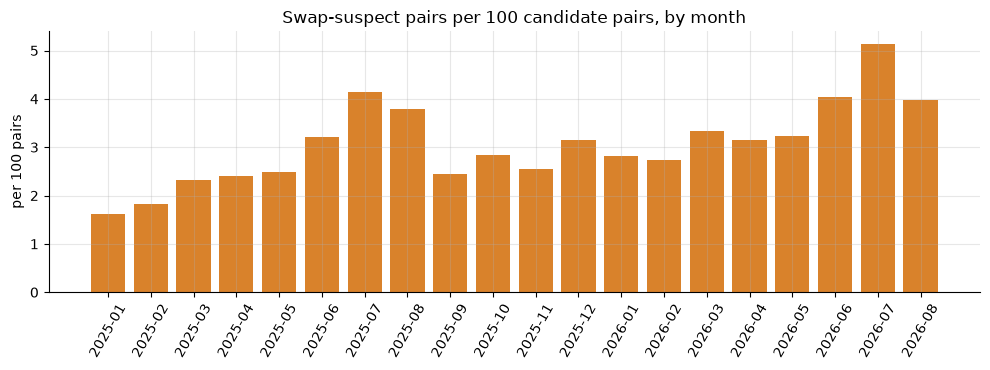

,month,swap_suspect_pairs,linked_turns,swap_per_100_candidate_pairs
0,2025-01,747,45438,1.62
1,2025-02,823,44478,1.82
2,2025-03,1278,53654,2.33
3,2025-04,1336,54169,2.41
4,2025-05,1443,56516,2.49
5,2025-06,1830,55031,3.22
6,2025-07,2360,54682,4.14
7,2025-08,2063,52363,3.79
8,2025-09,1260,50231,2.45
9,2025-10,1659,56941,2.83


In [7]:
print(f"swap-suspect pairs: {(breaks['reason'] == 'swap_suspect').sum():,}")
sm = R.swaps_by_month(breaks, turns)
fig, ax = plt.subplots()
ax.bar(sm["month"], sm["swap_per_100_candidate_pairs"], color=ORANGE)
ax.set_title("Swap-suspect pairs per 100 candidate pairs, by month"); ax.set_ylabel("per 100 pairs")
ax.tick_params(axis="x", rotation=60); plt.tight_layout(); plt.show()
sm

In [8]:
R.swaps_by_station(breaks, turns)

,station,swap_suspect_pairs,linked_turns,swap_per_100_candidate_pairs
0,ORD,4603,66689,6.46
1,DFW,11139,188938,5.57
2,PHL,2459,50498,4.64
3,LAX,1473,31862,4.42
4,MIA,2011,49320,3.92
5,DCA,1123,28949,3.73
6,PHX,2646,68455,3.72
7,CLT,5645,149401,3.64
8,LGA,534,16680,3.10
9,JFK,317,12290,2.51


In [9]:
R.swap_size_distribution(breaks)

,next departure scheduled before arrival by (min),pairs,pct
0,<=15,8835,26.4
1,15-30,6570,19.6
2,30-60,8700,26.0
3,60-120,6626,19.8
4,>120,2730,8.2


**What this shows.** **33,461 pairs (3.1% of candidate pairs)** are swap suspects. The rate follows disruption: it is
1.6% in January 2025, peaks in summer (4.1% in July 2025, **5.1% in July 2026**) and is higher in summer 2026 than summer 2025 (June 3.2% to 4.0%).
It concentrates at the biggest hubs: **ORD 6.5%, DFW 5.6%, PHL 4.6%, LAX 4.4%, MIA 3.9%**, against about 1% at BOS and SFO.
That is where an operations control centre has spare aircraft to substitute. The size of the conflict is small for many pairs:
26% are within 15 minutes, 72% within an hour, 8% more than two hours. Either the planned aircraft was replaced or the
schedule was tight; BTS cannot tell us which. Either way the pair is not a reliable link, so it breaks the chain.

## 3. Scheduled ground time, estimated MTT and planned buffer

**MTT is an assumption, estimated from train data only.** When the inbound flight arrived late *and* the
outbound flight left late, the aircraft was probably turned as fast as possible, so the low tail of the
**actual** ground time on those turns approximates the minimum. Estimate = the 10th percentile of actual ground
time per station and time-of-day band (morning 05–09, midday 10–14, afternoon 15–19, night 20–04, local time of
the outbound departure), using only **train** turns with a valid (positive) ground time. Fallback when a cell
has fewer than 50 such turns: station class (`high_volume` = at least 20 train turns/day, 13 stations) by band,
then one global value. Floor **25 min** (below the 1st percentile of observed pressured turns, about 32; it never binds, the lowest raw estimate is 27), cap
**60 min** (above every high-volume and mainland estimate, which top out around 55; it binds for HNL and one ANC cell, see below). `planned_buffer_min = max(0, scheduled ground − MTT)`.

**No validate or test turn is used to estimate MTT** (enforced by a unit test).

In [10]:
est = pd.read_csv(config.processed_dir() / "mtt_estimates.csv")
display(est[est["level"] != "station_band"].round(1))
print("station-band cells:", int((est["level"] == "station_band").sum()), "| with at least 50 pressured train turns:",
      int(((est["level"] == "station_band") & est["used"]).sum()))
R.mtt_source_share(turns)

,level,station,station_class,tod_band,n,raw_min,mtt_min,used,percentile
382,class_band,NaN,high_volume,afternoon,32583,47.0,47.0,True,0.1
383,class_band,NaN,high_volume,midday,21621,47.0,47.0,True,0.1
384,class_band,NaN,high_volume,morning,5882,46.0,46.0,True,0.1
385,class_band,NaN,high_volume,night,20959,48.0,48.0,True,0.1
386,class_band,NaN,other,afternoon,22497,37.0,37.0,True,0.1
387,class_band,NaN,other,midday,18724,39.0,39.0,True,0.1
388,class_band,NaN,other,morning,1541,37.0,37.0,True,0.1
389,class_band,NaN,other,night,3654,38.0,38.0,True,0.1
390,global,NaN,NaN,NaN,127461,42.0,42.0,True,0.1


station-band cells: 382 | with at least 50 pressured train turns: 244


,mtt_source,pct_of_turns
0,station_band,97.22
1,class_band,2.78


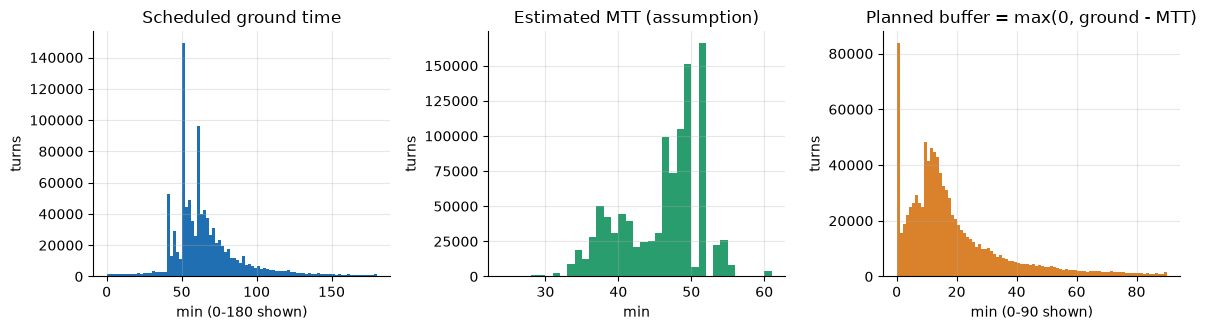

turns 1,045,807: median scheduled ground 60 min, median MTT 47 min, median planned buffer 14 min (mean 26.2)
zero planned buffer: 7.7% | under 15 min: 50.9% | scheduled below MTT: 6.9%


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
g = turns["sched_ground_min"]; g = g[(g >= 0) & (g <= 180)]
axes[0].hist(g, bins=90, color=BLUE); axes[0].set_title("Scheduled ground time"); axes[0].set_xlabel("min (0-180 shown)")
axes[1].hist(turns["mtt_min"], bins=np.arange(24, 62, 1), color=GREEN); axes[1].set_title("Estimated MTT (assumption)"); axes[1].set_xlabel("min")
b = turns["planned_buffer_min"]; b = b[b <= 90]
axes[2].hist(b, bins=90, color=ORANGE); axes[2].set_title("Planned buffer = max(0, ground - MTT)"); axes[2].set_xlabel("min (0-90 shown)")
for a in axes: a.set_ylabel("turns")
plt.tight_layout(); plt.show()
print(f"turns {len(turns):,}: median scheduled ground {turns['sched_ground_min'].median():.0f} min, median MTT {turns['mtt_min'].median():.0f} min,"
      f" median planned buffer {turns['planned_buffer_min'].median():.0f} min (mean {turns['planned_buffer_min'].mean():.1f})")
print(f"zero planned buffer: {100*(turns['planned_buffer_min']==0).mean():.1f}% | under 15 min: {100*(turns['planned_buffer_min']<15).mean():.1f}%"
      f" | scheduled below MTT: {100*turns['flag_below_mtt'].mean():.1f}%")

In [12]:
R.buffer_summary(turns, ['station_class', 'tod_band'])

,station_class,tod_band,turns,sched_ground_p50,mtt_p50,buffer_p50,buffer_mean,zero_buffer_pct,buffer_under_15_pct
0,high_volume,afternoon,231353,64.0,49.0,16.0,27.0,10.1,46.7
1,high_volume,midday,249961,63.0,48.0,15.0,24.5,10.9,48.0
2,high_volume,morning,110527,69.0,46.0,21.0,34.2,9.3,35.5
3,high_volume,night,125683,70.0,49.0,21.0,37.9,8.3,35.0
4,other,afternoon,132711,50.0,37.0,13.0,18.8,1.8,60.5
5,other,midday,150402,50.0,40.0,9.0,11.8,3.8,80.7
6,other,morning,18869,52.0,37.0,14.0,55.7,1.6,51.2
7,other,night,26301,65.0,46.0,20.1,44.9,2.2,38.1


In [13]:
R.buffer_summary(turns, ['split'])

,split,turns,sched_ground_p50,mtt_p50,buffer_p50,buffer_mean,zero_buffer_pct,buffer_under_15_pct
0,test,420953,60.0,47.0,13.0,25.2,9.4,54.0
1,train,466562,61.0,47.0,15.0,27.0,6.4,48.5
2,validate,158292,61.0,47.0,15.0,26.6,6.7,49.8


**Sensitivity to the MTT percentile** (all turns, then train turns only):

In [14]:
display(R.sensitivity_summary(sens))
R.sensitivity_summary(sens, "train")

,mtt_percentile,mtt_median_min,zero_buffer_pct,buffer_under_15_pct,buffer_median_min,buffer_mean_min
0,p05,44.0,5.69,39.63,17.0,28.94
1,p10,47.0,7.68,50.92,14.0,26.23
2,p20,51.0,13.90,60.78,11.0,23.10


,mtt_percentile,mtt_median_min,zero_buffer_pct,buffer_under_15_pct,buffer_median_min,buffer_mean_min
0,p05,44.0,4.68,37.27,18.0,29.80
1,p10,47.0,6.42,48.54,15.0,27.05
2,p20,51.0,12.09,58.82,12.0,23.86


**What this shows.** Across the 1,045,807 turns the **median scheduled ground time is 60 min** and the **median
estimated MTT is 47 min**, so the **median planned buffer is only 14 min** (mean 26). **7.7% of turns have zero planned
buffer** (6.4% in train, 9.4% in test) and **50.9% have under 15 minutes**; 6.9% are scheduled below MTT.

**MTT estimates (assumption).** Global value 42 min from 127,461 pressured train turns (27% of train turns). By class: **46-48 min at
high-volume stations** and **37-39 min elsewhere**, a plausible narrowbody turn. 97.2% of turns use a station-by-band
estimate (the rest the class fallback). High-volume stations have more zero-buffer turns (8-11%) than other stations (2-4%).

**The cap binds in one place.** For **HNL** (three cells, raw 10th percentile of 71-87 min) and ANC at night (60 min) the raw estimate is at or above
the 60-minute cap, so MTT is capped for **3,736 turns (0.36%)**, probably because long Pacific flights need longer turns. For those turns MTT is
understated and planned buffer overstated. The floor never binds (lowest raw estimate 27 min).

**Sensitivity.** Moving the percentile from p05 to p20 moves the median MTT from 44 to 51 min and the **zero-buffer share
from 5.7% to 13.9%** (under 15 min: 39.6% to 60.8%; median buffer 17 to 11 min). The default p10 is in the middle: the 10th
percentile of "time actually needed when pressed" is a conservative but not extreme definition of the minimum.

## 4. Key premise check: does planned buffer absorb delay?

Train turns where the inbound flight arrived late (`inbound_arr_delay > 0`). Two views:

* the **pass-through slope** of outbound departure delay on inbound arrival delay, by planned-buffer bucket,
  with 95% confidence intervals (cluster-robust, clustered by chain segment because turns in one chain are not independent);
* the **absorption table**: mean outbound departure delay for the same inbound delay band, by buffer bucket. A
  straight line is a blunt summary here because absorption is piecewise (delay up to the buffer disappears, the rest passes through).

,buffer_bucket,n,slope,ci_low,ci_high,intercept,mean_inbound_delay,mean_outbound_dep_delay,share_outbound_late15_pct
0,0,9208,1.088,1.036,1.140,29.000,31.654,63.441,87.011
1,1-15,75590,1.096,1.076,1.116,6.574,35.614,45.602,60.774
2,16-30,41106,1.056,1.032,1.080,-2.006,31.951,31.722,45.791
3,31-60,23998,0.951,0.911,0.990,-9.382,35.662,24.522,34.936
4,60+,23025,0.439,0.407,0.471,-6.544,68.171,23.394,30.979


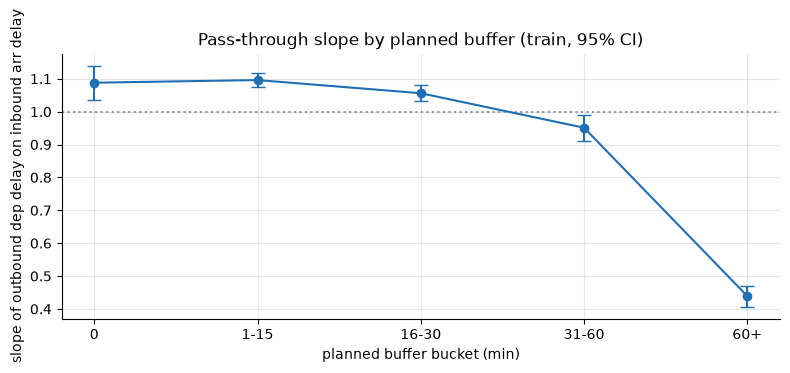

In [15]:
ps = R.passthrough_by_buffer(turns)
display(ps)
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(ps))
ax.errorbar(x, ps["slope"], yerr=[ps["slope"] - ps["ci_low"], ps["ci_high"] - ps["slope"]], fmt="o-", color=BLUE, capsize=5)
ax.axhline(1, color=GREY, ls=":"); ax.set_xticks(x); ax.set_xticklabels(ps["buffer_bucket"])
ax.set_xlabel("planned buffer bucket (min)"); ax.set_ylabel("slope of outbound dep delay on inbound arr delay")
ax.set_title("Pass-through slope by planned buffer (train, 95% CI)"); plt.tight_layout(); plt.show()

,inbound_delay_band,buffer_bucket,turns,mean_inbound_delay,mean_outbound_dep_delay,outbound_dep_late15_pct
0,1-15,0,4408,6.9,37.4,74.1
1,1-15,1-15,34042,6.9,14.0,23.9
2,1-15,16-30,19307,7.0,7.5,14.8
3,1-15,31-60,9924,7.0,5.4,12.1
4,1-15,60+,5885,7.1,8.7,14.1
5,16-30,0,1914,22.1,52.2,97.1
6,16-30,1-15,15317,22.1,31.0,76.0
7,16-30,16-30,8482,22.1,18.1,39.4
8,16-30,31-60,4899,22.3,9.3,16.6
9,16-30,60+,3269,22.5,8.9,14.6


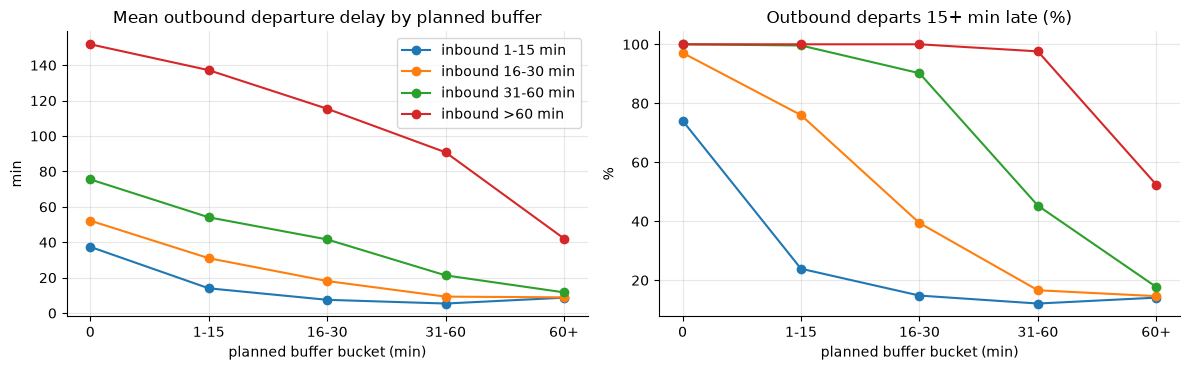

In [16]:
ab = R.absorption_table(turns)
display(ab)
pv = ab.pivot(index="buffer_bucket", columns="inbound_delay_band", values="mean_outbound_dep_delay")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for c in pv.columns: axes[0].plot(pv.index.astype(str), pv[c], marker="o", label=f"inbound {c} min")
axes[0].set_title("Mean outbound departure delay by planned buffer"); axes[0].set_xlabel("planned buffer bucket (min)"); axes[0].set_ylabel("min"); axes[0].legend()
pl = ab.pivot(index="buffer_bucket", columns="inbound_delay_band", values="outbound_dep_late15_pct")
for c in pl.columns: axes[1].plot(pl.index.astype(str), pl[c], marker="o", label=f"inbound {c} min")
axes[1].set_title("Outbound departs 15+ min late (%)"); axes[1].set_xlabel("planned buffer bucket (min)"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

Same slope table separately for high-volume stations and other stations (guards against a composition effect):

In [17]:
R.controlled_passthrough(turns)

,station_class,buffer_bucket,n,slope,ci_low,ci_high,intercept,mean_inbound_delay,mean_outbound_dep_delay,share_outbound_late15_pct
0,high_volume,0,8135,1.129,1.066,1.193,29.331,29.994,63.197,88.605
1,high_volume,1-15,37958,1.101,1.074,1.127,4.598,30.159,37.797,56.923
2,high_volume,16-30,29531,1.034,1.010,1.058,-2.453,28.581,27.102,42.938
3,high_volume,31-60,20338,0.927,0.884,0.969,-9.121,35.252,23.545,35.053
4,high_volume,60+,19076,0.398,0.375,0.420,-4.318,71.830,24.253,33.838
5,other,0,1073,1.009,0.926,1.092,20.679,44.236,65.295,74.930
6,other,1-15,37632,1.087,1.060,1.115,8.764,41.115,53.474,64.658
7,other,16-30,11575,1.069,1.026,1.111,0.174,40.550,43.507,53.071
8,other,31-60,3660,1.025,0.940,1.111,-8.951,37.941,29.951,34.290
9,other,60+,3949,0.634,0.538,0.731,-12.782,50.496,19.244,17.169


**Reading the result honestly.** The premise holds, but the straight-line slope is not what shows it.

* **Slopes (train, 95% CI):** 1.09 [1.04, 1.14] at zero buffer, 1.10 [1.08, 1.12] at 1-15, 1.06 [1.03, 1.08] at 16-30,
  **0.95 [0.91, 0.99] at 31-60 and 0.44 [0.41, 0.47] at 60+**. The slope falls as buffer rises, but only beyond ~30 minutes
  of buffer; below that it is flat at about 1. At zero buffer it is above 1 because turns scheduled *below* MTT
  also lose the shortfall (the intercept is +29 min).
* **Absorption table (the clearer view).** For the same inbound delay, outbound delay falls steeply with buffer. For a
  16-30 minute inbound delay (mean 22): outbound departure delay **52 min at zero buffer, 31 at 1-15, 18 at 16-30, 9 at 31-60** and the share
  leaving 15+ minutes late falls from **97% to 76%, 39%, 17%**. For 31-60 minutes inbound (mean 43): 76, 54, 42, 21, 12 min. For more than 60
  minutes inbound (mean 110-130): 152, 137, 115, 91, **42** min. Roughly **one minute of delay is absorbed per extra minute of buffer
  until the buffer exceeds the inbound delay**, after which more buffer adds little (diminishing returns).
* **Composition check.** Within high-volume stations and within other stations the pattern is the same (high-volume slopes 1.13, 1.10, 1.03, 0.93, 0.40).

**Caveats.** Buffer is not randomly assigned; stations, aircraft and times of day differ, so this is strong
association rather than proof of causation. Bucket boundaries depend on the MTT assumption. Inbound delay is
comparable across buckets (e.g. 22.1-22.5 min in the 16-30 band), which makes the comparison like-for-like on the inbound side.

## 5. Pass-through by position in the day and by hour

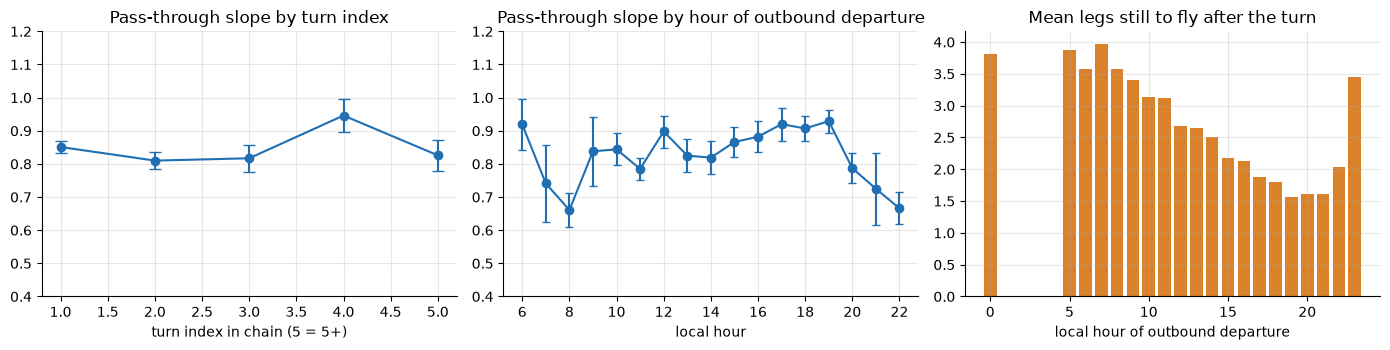

,turn_index,n,slope,ci_low,ci_high,intercept,mean_inbound_delay,mean_outbound_dep_delay,share_outbound_late15_pct
0,1,54532,0.851,0.832,0.869,2.022,47.805,42.682,51.753
1,2,46651,0.810,0.785,0.835,8.249,36.709,37.982,52.931
2,3,34768,0.817,0.777,0.856,5.919,34.303,33.929,50.785
3,4,18667,0.946,0.897,0.996,2.203,33.649,34.048,49.349
4,5,18309,0.826,0.780,0.871,3.657,31.797,29.909,46.463


,hour,n,slope,ci_low,ci_high,intercept,mean_inbound_delay,mean_outbound_dep_delay,share_outbound_late15_pct
0,6,321,0.919,0.841,0.997,-6.512,28.614,19.791,31.153
1,7,1687,0.741,0.625,0.856,-3.963,21.956,12.298,23.829
2,8,4989,0.661,0.610,0.711,-0.736,23.899,15.051,28.242
3,9,5815,0.838,0.734,0.941,2.295,26.709,24.667,38.315
4,10,10130,0.844,0.796,0.892,0.328,29.779,25.465,39.990
5,11,10955,0.785,0.751,0.819,4.439,31.428,29.107,44.811
6,12,10867,0.898,0.849,0.946,7.703,35.910,39.940,52.093
7,13,10751,0.825,0.775,0.875,8.604,36.903,39.043,52.349
8,14,11424,0.819,0.770,0.868,8.787,36.823,38.942,54.359
9,15,11466,0.866,0.822,0.910,7.853,38.795,41.461,55.486


In [18]:
ti = R.passthrough_by_turn_index(turns)
hr = R.passthrough_by_hour(turns)
dh = R.downstream_by_hour(turns)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].errorbar(ti["turn_index"], ti["slope"], yerr=[ti["slope"] - ti["ci_low"], ti["ci_high"] - ti["slope"]], fmt="o-", color=BLUE, capsize=4)
axes[0].set_title("Pass-through slope by turn index"); axes[0].set_xlabel("turn index in chain (5 = 5+)"); axes[0].set_ylim(0.4, 1.2)
axes[1].errorbar(hr["hour"], hr["slope"], yerr=[hr["slope"] - hr["ci_low"], hr["ci_high"] - hr["slope"]], fmt="o-", color=BLUE, capsize=3)
axes[1].set_title("Pass-through slope by hour of outbound departure"); axes[1].set_xlabel("local hour"); axes[1].set_ylim(0.4, 1.2)
d = dh[(dh["turns"] >= 1000)]
axes[2].bar(d["hour"], d["mean_downstream_legs"], color=ORANGE)
axes[2].set_title("Mean legs still to fly after the turn"); axes[2].set_xlabel("local hour of outbound departure")
plt.tight_layout(); plt.show()
display(ti)
display(hr)

**What this shows.** The claim "early delays cause more downstream damage" is supported by **exposure, not by a higher pass-through per turn**.

* **Slope by turn index** shows no trend (0.85, 0.81, 0.82, 0.95, 0.83): a late turn passes delay on about as much as an early one.
* **Slope by hour** is actually lower in the morning (0.66-0.84 at 07:00-11:00, probably because morning buffers are
  longer: median 21 min vs 15-16 in the afternoon at high-volume stations) and about 0.9 from 17:00 to 19:00.
* **Exposure:** the mean number of legs still to fly after the turn is **3.1-4.0 for turns before 11:00 and 1.6-1.9 between 17:00 and 21:59**.
  A delay minute passed on at a morning turn can hit 3-4 more legs, one in the evening only about 1.6.

So early-day buffer matters because of what is downstream; the simulator must model that chain effect explicitly rather than rely
on a per-turn slope. Note `leg_index_in_segment` and `n_downstream_legs` come from the *realised* chain: a segment cut
short by a cancellation or swap understates the planned number of downstream legs.

## 6. Comparison with BTS `LateAircraftDelay` (aggregate sanity check only)

BTS attributes `LateAircraftDelay` only to arrivals of 15+ minutes, so this is a comparison of averages by inbound delay band, never flight by flight.

,inbound_delay_bin,turns,mean_inbound_arr_delay,mean_outbound_dep_delay_floor0,mean_bts_late_aircraft_delay_outbound,outbound_arr_late15_pct,outbound_has_late_aircraft_pct
0,1-15,73566,6.95,13.95,1.73,23.40,13.23
1,16-30,33881,22.17,24.53,6.71,41.41,36.30
2,31-60,31122,43.28,41.95,20.32,69.20,65.41
3,61-120,22430,84.70,72.56,48.59,82.57,79.05
4,>120,12028,188.57,155.24,120.56,88.29,85.62


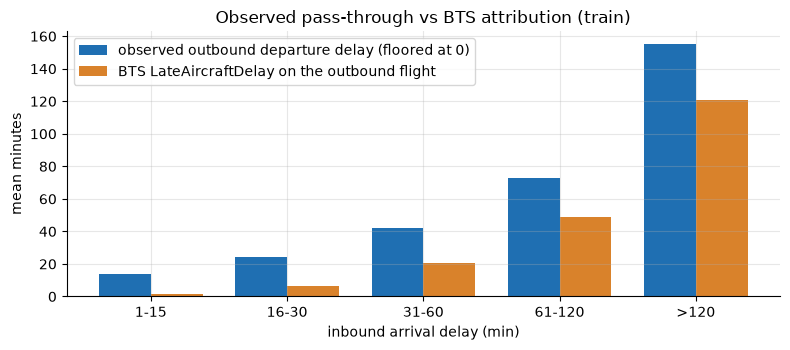

In [19]:
lc = R.late_aircraft_comparison(turns)
display(lc)
x = np.arange(len(lc)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - w/2, lc["mean_outbound_dep_delay_floor0"], w, color=BLUE, label="observed outbound departure delay (floored at 0)")
ax.bar(x + w/2, lc["mean_bts_late_aircraft_delay_outbound"], w, color=ORANGE, label="BTS LateAircraftDelay on the outbound flight")
ax.set_xticks(x); ax.set_xticklabels(lc["inbound_delay_bin"]); ax.set_xlabel("inbound arrival delay (min)"); ax.set_ylabel("mean minutes")
ax.legend(); ax.set_title("Observed pass-through vs BTS attribution (train)"); plt.tight_layout(); plt.show()

**What this shows.** Both measures rise steadily with the inbound delay, which is the expected direction. BTS `LateAircraftDelay` is
smaller than the observed departure delay passed on, and the share grows with the inbound delay: about **12%** for 1-15 min inbound, **27%** for 16-30,
**48%** for 31-60, **67%** for 61-120 and **78%** above 120. That is what we would expect, because BTS attributes delay only to arrivals of
15+ minutes and only the part not assigned to other causes (for 16-30 minutes inbound, 41% of outbound flights arrive 15+ late
but only 36% have any late-aircraft delay recorded). Observed pass-through is therefore an upper bound on what BTS records;
the two are consistent in direction and order of magnitude, and BTS `LateAircraftDelay` is usable for validating the simulator **in aggregate** only.

## 7. Storm days and high-cancellation days

`storm_day_flag` = 2026-01-24 to 2026-01-28. `high_cancel_day` = any day on which more than 10% of the day's flights were cancelled.

,flight_date,flights,cancelled_pct,usable_pct,storm_day_flag,high_cancel_day,turns,mean_outbound_dep_delay,storm_flag_turns
0,2026-01-20,2370,0.0,88.9,False,False,1532,4.3,0
1,2026-01-21,2368,0.0,88.4,False,False,1518,2.2,0
2,2026-01-22,2593,0.0,88.7,False,False,1677,6.8,0
3,2026-01-23,2577,3.8,82.5,False,False,1542,10.5,0
4,2026-01-24,2233,41.7,37.7,True,True,544,27.4,544
5,2026-01-25,2568,67.3,16.3,True,True,263,66.9,263
6,2026-01-26,2510,65.8,15.2,True,True,224,208.8,224
7,2026-01-27,2367,53.4,25.6,True,True,351,102.9,351
8,2026-01-28,2372,19.6,60.7,True,True,936,50.4,936
9,2026-01-29,2587,0.4,86.7,False,False,1618,22.8,0


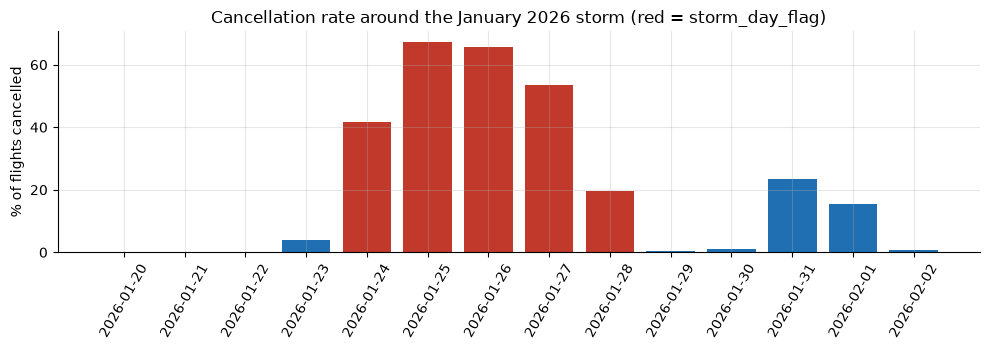

turns flagged storm_day_flag: 2318 | all on 2026-01-24..28: True | flagged turns outside that range: 0
days with more than 10% cancelled: 27 | turns on those days: 30866


,flight_date,flights,cancelled,usable_pct,storm_day_flag,high_cancel_day,cancelled_pct
0,2025-01-09,2606,735,52.2,False,True,28.2
1,2025-01-10,2469,670,52.0,False,True,27.1
2,2025-03-04,2420,278,70.5,False,True,11.5
3,2025-04-30,2761,355,68.6,False,True,12.9
4,2025-07-12,2705,298,71.2,False,True,11.0
5,2025-07-13,2913,428,68.9,False,True,14.7
6,2025-07-14,2928,348,72.5,False,True,11.9
7,2025-08-30,2246,294,66.1,False,True,13.1
8,2025-09-19,2593,317,73.4,False,True,12.2
9,2025-11-09,2848,325,74.5,False,True,11.4


In [20]:
sw = R.storm_window(legs, turns)
display(sw)
fig, ax = plt.subplots(figsize=(10, 3.6))
cols = [RED if f else BLUE for f in sw["storm_day_flag"]]
ax.bar(sw["flight_date"].astype(str), sw["cancelled_pct"], color=cols); ax.set_ylabel("% of flights cancelled")
ax.tick_params(axis="x", rotation=60); ax.set_title("Cancellation rate around the January 2026 storm (red = storm_day_flag)")
plt.tight_layout(); plt.show()
print("turns flagged storm_day_flag:", int(turns["storm_day_flag"].sum()), "| all on 2026-01-24..28:",
      bool(turns.loc[turns["storm_day_flag"], "outbound_flight_date"].between(pd.Timestamp("2026-01-24"), pd.Timestamp("2026-01-28")).all()),
      "| flagged turns outside that range:", int((~turns["outbound_flight_date"].between(pd.Timestamp("2026-01-24"), pd.Timestamp("2026-01-28")) & turns["storm_day_flag"]).sum()))
print("days with more than 10% cancelled:", int(legs.drop_duplicates("flight_date")["high_cancel_day"].sum()),
      "| turns on those days:", int(turns["high_cancel_day"].sum()))
R.high_cancel_days(legs)

**What this shows.** The January 2026 storm is clearly visible and **correctly flagged**: all 2,318 turns on 2026-01-24 to 2026-01-28
carry `storm_day_flag` and none outside that range. Cancellations reached 42%, 67%, 66%, 53% and 20% of flights on those days; usable
chains shrink to 15-38% of flights on 24-27 January and 61% on the 28th (normal: about 85-89%); turns fall from about 1,500-1,700 per day to 224-936; the mean outbound
departure delay rises from 2-10 minutes before the storm to **27, 67, 209, 103 and 50 minutes**, and stays elevated (17-24 min) for days afterwards.

`high_cancel_day` flags 27 days with more than 10% of flights cancelled (30,866 turns), including 31 January and 1 February 2026, which are
after the storm window and therefore not storm-flagged, and 9-10 January 2025 (28% and 27%) in the **train** period. Backtests should
be reported with and without these days.

## 8. Conclusion

### Usable for Phases 3 to 6

* **1,408,848 legs in 363,041 usable segments and 1,045,807 turns** (train 466,562, validate 158,292, test 420,953), about 1,700
  turns per day: a size an exact solver can handle day by day.
* **A defensible MTT and planned buffer**, with a sensitivity table for p05 / p10 / p20, estimated from train data only.
* **Observed pass-through by buffer level**: the evidence that buffer absorbs delay (section 4), to calibrate and validate the simulator.
* **Storm and high-cancellation flags** to run backtests with and without disrupted days.
* **A complete reconciliation**: every base flight is in one category, enforced by a test.

### Limitations and risks

1. **Planned rotation is assumed to equal the operated rotation.** BTS gives the aircraft that actually flew. 33,461 pairs (3.1% of
   candidate pairs) show the plan and the operation disagree, and they are broken, not repaired. Segments are therefore shorter than
   the planned rotations and `n_downstream_legs` is a lower bound on the true downstream exposure.
2. **MTT is an assumption.** The zero-buffer share moves between 5.7% and 13.9% across p05-p20, and every buffer figure shifts with it.
   The optimiser results must be shown with that sensitivity.
3. **Buffer is already thin and the budget is small.** The median planned buffer is 14 min and half of all turns have under 15. The network
   already holds about 45,000 buffer minutes per day (1,720 turns x 26 min on average); a budget of 500 extra minutes per day is about 1% of that,
   so the optimiser is really choosing where to add a small increment. Absorption saturates once buffer exceeds the likely inbound
   delay, so the marginal value of a minute is highest on short buffers that precede delay-prone arrivals.
4. **Leakage.** `leg_index_in_segment`, `n_legs`, `n_downstream_legs`, `segment_id`, `break_reason_*` and `n_segments` depend on cancellations and
   swaps that happen on the day, so they must not be prediction features until the leakage review before modelling.
5. **Discarded or excluded:** 191,021 single-leg-segment flights, 35,245 cancelled and 5,957 diverted flights, and any pair separated by a rest of more than 300
   minutes (overnight): delay does not carry across those, and nothing is lost by the rule since the next day starts a new operating day.
6. **Disrupted days distort averages** (27 high-cancellation days, five of them the storm). Report with and without.
7. **Pass-through is association.** Buffer is not randomly assigned. The simulator should be validated against observed outcomes, not assumed causal.